# Classification de fleurs (Daisy / Rose / Tulip) — Softmax, k-NN, CNN + Vote

Ce notebook regroupe l'entraînement des **trois modèles**, leurs **métriques**, leurs **graphiques**, puis un **modèle de vote** (ensemble) qui combine les trois.

**Ce qui a été changé pour réduire l'overfitting**

| Modèle | Problème avant | Correction |
|---|---|---|
| **CNN** | `Flatten` sur une carte 36×36×64 → ~5 M de paramètres dans le `Dense` pour ~1 000 images → mémorisation | 4 blocs Conv + **BatchNorm**, **GlobalAveragePooling** (≈ 400 k paramètres), Dropout, augmentation plus riche, `class_weight` |
| **Softmax** | C'était en fait un MLP (32-16) sur 67 500 pixels bruts | Vrai **softmax regression** (1 seule couche) sur image réduite 32×32 + normalisation + L2 |
| **k-NN** | Distance sur 67 500 pixels bruts (malédiction de la dimension) | Image réduite 32×32 + **PCA** + recherche de `k`, distance et pondération sur la validation |
| **Évaluation** | Seulement l'accuracy test | Accuracy train/val/test (**écart d'overfitting**), précision, rappel, F1, matrices de confusion, F1 par classe |
| **Vote** | — | Vote dur, vote doux et vote **pondéré** (poids choisis sur la validation uniquement) |

In [1]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix, log_loss)
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Hyper-paramètres principaux ----
EPOCHS_SOFTMAX = 100
EPOCHS_CNN     = 80
BATCH_SIZE     = 32
KNN_RES        = 32     # résolution utilisée pour k-NN et Softmax (32x32)

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})

I0000 00:00:1793982754.168690  121014 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793982754.170881  121014 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793982754.422795  121014 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793982755.853150  121014 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

## 1. Chargement des données

In [3]:
for path in ['tf_flowers_prepared.npz', '../tf_flowers_prepared.npz']:
    if os.path.exists(path):
        DATA_PATH = path
        break
else:
    raise FileNotFoundError("tf_flowers_prepared.npz introuvable : lancez d'abord prepare_data_v2.ipynb")

data = np.load(DATA_PATH)

def to_float01(a):
    # accepte uint8 (0-255) ou float déjà normalisé (0-1)
    a = a.astype('float32')
    return a / 255.0 if a.max() > 1.5 else a

X_train, y_train = to_float01(data['X_train']), data['y_train'].astype(int)
X_val,   y_val   = to_float01(data['X_val']),   data['y_val'].astype(int)
X_test,  y_test  = to_float01(data['X_test']),  data['y_test'].astype(int)
class_names = [str(c) for c in data['class_names']]

NUM_CLASSES = len(class_names)
INPUT_SHAPE = X_train.shape[1:]

print("Données :", DATA_PATH)
print("Train :", X_train.shape, "| Val :", X_val.shape, "| Test :", X_test.shape)
print("Pixels :", X_train.min(), "->", X_train.max())
print("Classes :", class_names)

# Poids de classes (compense le déséquilibre éventuel)
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print("class_weight :", {class_names[i]: round(w, 3) for i, w in class_weight.items()})

Données : tf_flowers_prepared.npz
Train : (1451, 128, 128, 3) | Val : (311, 128, 128, 3) | Test : (311, 128, 128, 3)
Pixels : 0.0 -> 1.0
Classes : ['Daisy', 'Rose', 'Tulip']
class_weight : {'Daisy': 1.092, 'Rose': 1.077, 'Tulip': 0.865}


## 2. Outils communs (métriques et graphiques)

In [4]:
results = {}                           # métriques par modèle
probs   = {'val': {}, 'test': {}}      # probabilités (utilisées par le vote)
test_pred = {}                         # prédictions test par modèle

def register(name, p_val, p_test, p_train=None, verbose=True):
    """Calcule et stocke toutes les métriques d'un modèle à partir de ses probabilités."""
    yv, yt = p_val.argmax(1), p_test.argmax(1)
    results[name] = {
        'Train Acc': accuracy_score(y_train, p_train.argmax(1)) if p_train is not None else np.nan,
        'Val Acc':   accuracy_score(y_val, yv),
        'Test Acc':  accuracy_score(y_test, yt),
        'Precision': precision_score(y_test, yt, average='macro', zero_division=0),
        'Recall':    recall_score(y_test, yt, average='macro', zero_division=0),
        'F1':        f1_score(y_test, yt, average='macro', zero_division=0),
    }
    for c, f in enumerate(f1_score(y_test, yt, average=None, zero_division=0)):
        results[name][f'F1 {class_names[c]}'] = f
    probs['val'][name], probs['test'][name], test_pred[name] = p_val, p_test, yt
    if verbose:
        r = results[name]
        print(f"=== {name} ===")
        print(f"Train acc: {r['Train Acc']:.4f} | Val acc: {r['Val Acc']:.4f} | Test acc: {r['Test Acc']:.4f}")
        print(f"Precision: {r['Precision']:.4f} | Recall: {r['Recall']:.4f} | F1: {r['F1']:.4f}  (macro, test)\n")
        print(classification_report(y_test, yt, target_names=class_names, zero_division=0))

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['accuracy'], label='Train'); ax[0].plot(h.history['val_accuracy'], label='Validation')
    ax[0].set(title=f'{title} — Accuracy', xlabel='Epoch', ylabel='Accuracy'); ax[0].legend()
    ax[1].plot(h.history['loss'], label='Train'); ax[1].plot(h.history['val_loss'], label='Validation')
    ax[1].set(title=f'{title} — Loss', xlabel='Epoch', ylabel='Loss'); ax[1].legend()
    plt.tight_layout(); plt.show()

def plot_confusion(name, ax=None, normalize=False):
    cm = confusion_matrix(y_test, test_pred[name], labels=range(NUM_CLASSES))
    if normalize:
        cm = cm / cm.sum(axis=1, keepdims=True)
    show = ax is None
    if show: _, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='.2f' if normalize else 'd', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set(title=f'{name}', xlabel='Prédit', ylabel='Réel'); ax.grid(False)
    if show: plt.tight_layout(); plt.show()

def downsample(X, size=KNN_RES):
    return tf.image.resize(X, [size, size], antialias=True).numpy()

## 3. Modèle 1 — Softmax (régression logistique multinomiale)

Une seule couche `Dense(3, softmax)` sur l'image réduite à 32×32 (3 072 entrées au lieu de 67 500).
La régularisation L2 limite la taille des poids ; la normalisation par canal accélère la convergence.

In [10]:
norm_layer = layers.Normalization(axis=-1)
norm_layer.adapt(X_train)                      # statistiques calculées sur le TRAIN uniquement

def build_softmax():
    return models.Sequential([
        layers.Input(shape=INPUT_SHAPE),
        norm_layer,
        layers.AveragePooling2D(pool_size=INPUT_SHAPE[0] // KNN_RES),   # 128 -> 32
        layers.Flatten(),
        layers.Dense(NUM_CLASSES, activation='softmax',
                     kernel_regularizer=regularizers.l2(1e-3)),
    ], name='softmax_regression')

softmax_model = build_softmax()
softmax_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
softmax_model.summary()

Model: "softmax_regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 128, 128, 3)    │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 32, 32, 3)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         9,219 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,226 (36.04 KB)

 Trainable params: 9,219 (36.01 KB)

 Non-trainable params: 7 (32.00 B)

In [11]:
hist_softmax = softmax_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_SOFTMAX, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[
        callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    ],
    verbose=2)

Epoch 1/100
46/46 - 2s - 35ms/step - accuracy: 0.4866 - loss: 1.1844 - val_accuracy: 0.5016 - val_loss: 1.2687 - learning_rate: 0.0010
Epoch 2/100
46/46 - 0s - 9ms/step - accuracy: 0.5879 - loss: 0.9163 - val_accuracy: 0.5080 - val_loss: 1.2898 - learning_rate: 0.0010
Epoch 3/100
46/46 - 0s - 9ms/step - accuracy: 0.6237 - loss: 0.8371 - val_accuracy: 0.5016 - val_loss: 1.3495 - learning_rate: 0.0010
Epoch 4/100
46/46 - 0s - 9ms/step - accuracy: 0.6451 - loss: 0.7866 - val_accuracy: 0.5016 - val_loss: 1.4117 - learning_rate: 0.0010
Epoch 5/100

Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
46/46 - 0s - 9ms/step - accuracy: 0.6726 - loss: 0.7514 - val_accuracy: 0.5080 - val_loss: 1.4755 - learning_rate: 0.0010
Epoch 6/100
46/46 - 0s - 9ms/step - accuracy: 0.7119 - loss: 0.6754 - val_accuracy: 0.5563 - val_loss: 1.1111 - learning_rate: 5.0000e-04
Epoch 7/100
46/46 - 0s - 10ms/step - accuracy: 0.7609 - loss: 0.6159 - val_accuracy: 0.5305 - val_loss: 1.1278 - l

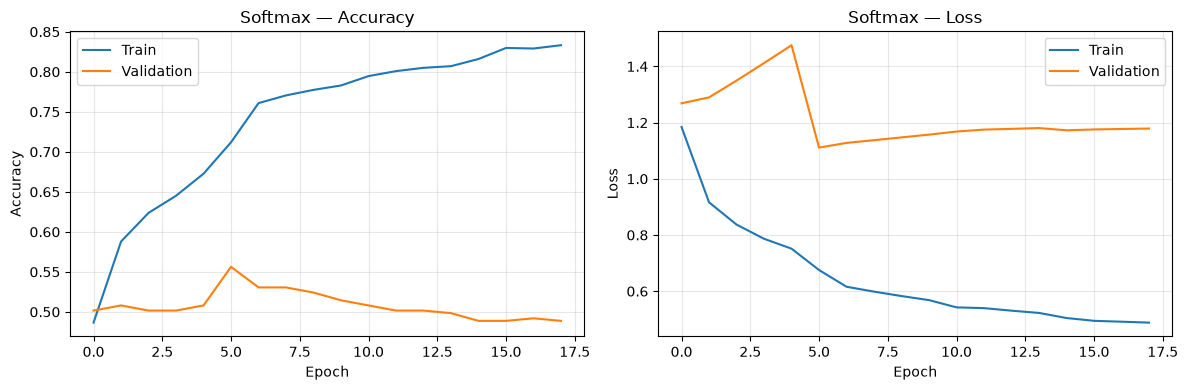

=== Softmax ===
Train acc: 0.7519 | Val acc: 0.5563 | Test acc: 0.5498
Precision: 0.5449 | Recall: 0.5466 | F1: 0.5451  (macro, test)

              precision    recall  f1-score   support

       Daisy       0.59      0.62      0.61        95
        Rose       0.48      0.43      0.45        96
       Tulip       0.57      0.59      0.58       120

    accuracy                           0.55       311
   macro avg       0.54      0.55      0.55       311
weighted avg       0.55      0.55      0.55       311



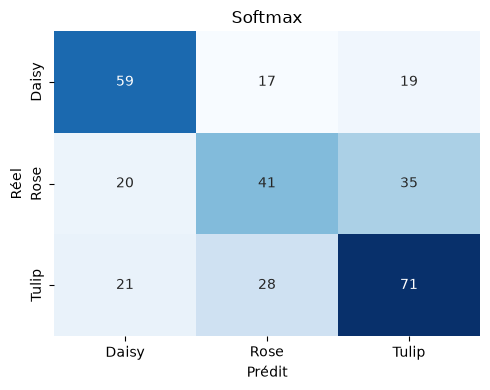

In [12]:
plot_history(hist_softmax, 'Softmax')

register('Softmax',
         softmax_model.predict(X_val, verbose=0),
         softmax_model.predict(X_test, verbose=0),
         softmax_model.predict(X_train, verbose=0))
plot_confusion('Softmax')

## 4. Modèle 2 — k-NN

Pipeline : image 32x32 → **PCA** (garde les directions qui portent le plus de variance, supprime le bruit) → k-NN.
On cherche sur la **validation** : le nombre de composantes PCA, `k`, la distance (L1 / L2 / cosinus) et la pondération (uniforme / par distance).

In [13]:
Xtr_s = downsample(X_train).reshape(len(X_train), -1)
Xva_s = downsample(X_val).reshape(len(X_val), -1)
Xte_s = downsample(X_test).reshape(len(X_test), -1)
print("Dimension après réduction :", Xtr_s.shape[1])

pca_options = [None, 50, 100]                  # None = pixels bruts (baseline)
k_values    = [1, 3, 5, 7, 9, 11, 15, 21]
metrics_opt = ['euclidean', 'manhattan', 'cosine']
weights_opt = ['uniform', 'distance']

rows = []
for n_comp in pca_options:
    if n_comp is None:
        Ztr, Zva = Xtr_s, Xva_s
    else:
        pca = PCA(n_components=n_comp, random_state=SEED).fit(Xtr_s)   # fit sur TRAIN seulement
        Ztr, Zva = pca.transform(Xtr_s), pca.transform(Xva_s)
    for metric in metrics_opt:
        for w in weights_opt:
            for k in k_values:
                knn = KNeighborsClassifier(n_neighbors=k, metric=metric, weights=w, n_jobs=-1).fit(Ztr, y_train)
                rows.append({'PCA': 'raw' if n_comp is None else n_comp, 'Distance': metric,
                             'Weights': w, 'K': k,
                             'Val Acc': accuracy_score(y_val, knn.predict(Zva))})

knn_df = pd.DataFrame(rows).sort_values('Val Acc', ascending=False).reset_index(drop=True)
display(knn_df.head(10))

Dimension après réduction : 3072


,PCA,Distance,Weights,K,Val Acc
0,100,euclidean,uniform,9,0.572347
1,100,manhattan,uniform,9,0.565916
2,100,euclidean,distance,9,0.562701
3,100,euclidean,distance,11,0.562701
4,100,manhattan,distance,21,0.559486
5,100,euclidean,uniform,11,0.559486
6,50,euclidean,uniform,11,0.559486
7,50,euclidean,distance,11,0.559486
8,100,manhattan,uniform,11,0.556270
9,100,manhattan,uniform,15,0.556270


Meilleure configuration (validation) :
 {'PCA': 100, 'Distance': 'euclidean', 'Weights': 'uniform', 'K': 9, 'Val Acc': 0.572347266881029}


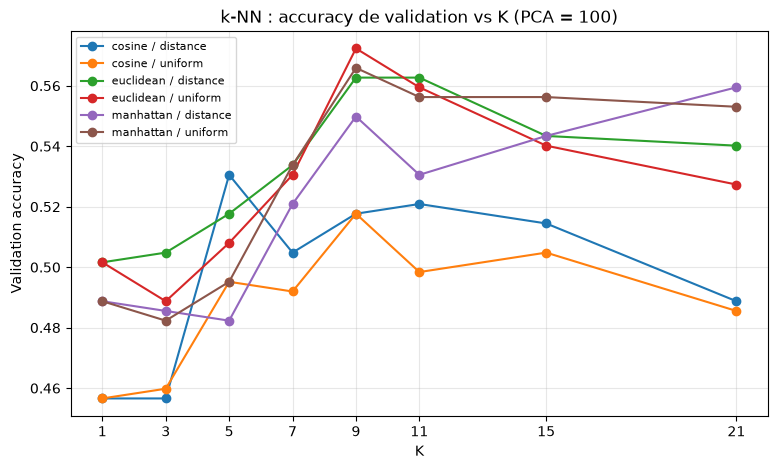

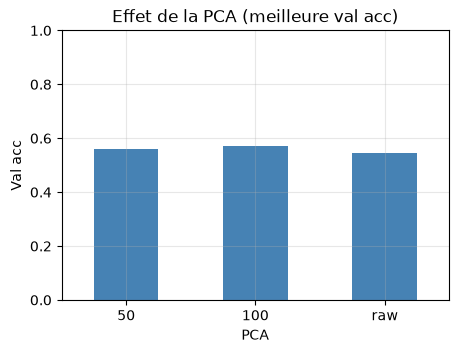

In [14]:
best = knn_df.iloc[0]
print("Meilleure configuration (validation) :\n", best.to_dict())

# Courbes : accuracy de validation en fonction de k, à PCA optimale
sub = knn_df[knn_df['PCA'] == best['PCA']]
plt.figure(figsize=(9, 5))
for (metric, w), g in sub.groupby(['Distance', 'Weights']):
    g = g.sort_values('K')
    plt.plot(g['K'], g['Val Acc'], marker='o', label=f'{metric} / {w}')
plt.title(f"k-NN : accuracy de validation vs K (PCA = {best['PCA']})")
plt.xlabel('K'); plt.ylabel('Validation accuracy'); plt.xticks(k_values); plt.legend(fontsize=8)
plt.show()

# Effet de la PCA (meilleure accuracy de validation pour chaque option)
plt.figure(figsize=(5, 3.5))
knn_df.groupby('PCA')['Val Acc'].max().plot(kind='bar', color='steelblue')
plt.title('Effet de la PCA (meilleure val acc)'); plt.ylabel('Val acc'); plt.xticks(rotation=0)
plt.ylim(0, 1); plt.show()

=== k-NN ===
Train acc: nan | Val acc: 0.5723 | Test acc: 0.5080
Precision: 0.5054 | Recall: 0.4955 | F1: 0.4934  (macro, test)

              precision    recall  f1-score   support

       Daisy       0.59      0.52      0.55        95
        Rose       0.42      0.31      0.36        96
       Tulip       0.50      0.66      0.57       120

    accuracy                           0.51       311
   macro avg       0.51      0.50      0.49       311
weighted avg       0.50      0.51      0.50       311



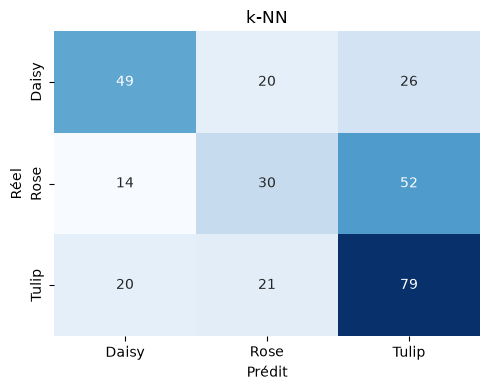

In [15]:
# Modèle final k-NN avec les meilleurs hyper-paramètres
if best['PCA'] == 'raw':
    transform = lambda A: A
else:
    pca_final = PCA(n_components=int(best['PCA']), random_state=SEED).fit(Xtr_s)
    transform = pca_final.transform

knn_final = KNeighborsClassifier(n_neighbors=int(best['K']), metric=best['Distance'],
                                 weights=best['Weights'], n_jobs=-1).fit(transform(Xtr_s), y_train)

# Pas d'accuracy train pour k-NN : chaque point serait son propre voisin (valeur trompeuse)
register('k-NN', knn_final.predict_proba(transform(Xva_s)), knn_final.predict_proba(transform(Xte_s)))
plot_confusion('k-NN')

## 5. Modèle 3 — CNN

- 4 blocs `Conv → BatchNorm → ReLU → MaxPool` (32, 64, 128, 256 filtres)
- **GlobalAveragePooling** à la place de `Flatten` : on passe de ~5 M à ~400 k paramètres
- Data augmentation (flip, rotation, zoom, contraste), active **uniquement** pendant l'entraînement
- Dropout + L2, `EarlyStopping` + `ReduceLROnPlateau`

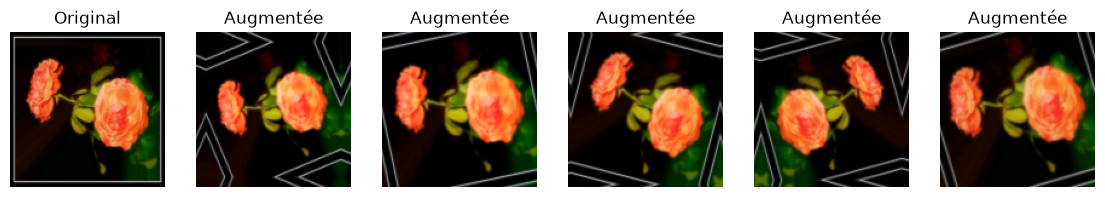

In [16]:
augmentation = models.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name='augmentation')

# Aperçu de l'augmentation sur une image
sample = X_train[0:1]
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(sample[0]); axes[0].set_title('Original')
for a in axes[1:]:
    a.imshow(np.clip(augmentation(sample, training=True)[0].numpy(), 0, 1)); a.set_title('Augmentée')
for a in axes: a.axis('off')
plt.show()

In [17]:
def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', use_bias=False,
                      kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return layers.MaxPooling2D(2)(x)

def build_cnn():
    inp = layers.Input(shape=INPUT_SHAPE)
    x = augmentation(inp)
    for f in (32, 64, 128, 256):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return models.Model(inp, out, name='cnn')

cnn_model = build_cnn()
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn_model.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 406,499 (1.55 MB)

 Trainable params: 405,539 (1.55 MB)

 Non-trainable params: 960 (3.75 KB)

In [18]:
hist_cnn = cnn_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS_CNN, batch_size=BATCH_SIZE,
    class_weight=class_weight,
    callbacks=[
        callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4, min_lr=1e-5, verbose=1),
    ],
    verbose=2)

Epoch 1/80
46/46 - 35s - 767ms/step - accuracy: 0.5327 - loss: 1.1067 - val_accuracy: 0.4341 - val_loss: 1.1043 - learning_rate: 0.0010
Epoch 2/80
46/46 - 31s - 679ms/step - accuracy: 0.5886 - loss: 0.9112 - val_accuracy: 0.5113 - val_loss: 1.1045 - learning_rate: 0.0010
Epoch 3/80
46/46 - 32s - 696ms/step - accuracy: 0.5955 - loss: 0.8914 - val_accuracy: 0.4984 - val_loss: 1.0679 - learning_rate: 0.0010
Epoch 4/80
46/46 - 33s - 716ms/step - accuracy: 0.6361 - loss: 0.8398 - val_accuracy: 0.4887 - val_loss: 1.0699 - learning_rate: 0.0010
Epoch 5/80
46/46 - 31s - 684ms/step - accuracy: 0.6540 - loss: 0.8065 - val_accuracy: 0.5113 - val_loss: 0.9993 - learning_rate: 0.0010
Epoch 6/80
46/46 - 32s - 690ms/step - accuracy: 0.6513 - loss: 0.7940 - val_accuracy: 0.6013 - val_loss: 0.9047 - learning_rate: 0.0010
Epoch 7/80
46/46 - 31s - 666ms/step - accuracy: 0.6465 - loss: 0.8066 - val_accuracy: 0.6302 - val_loss: 0.8535 - learning_rate: 0.0010
Epoch 8/80
46/46 - 32s - 693ms/step - accuracy: 

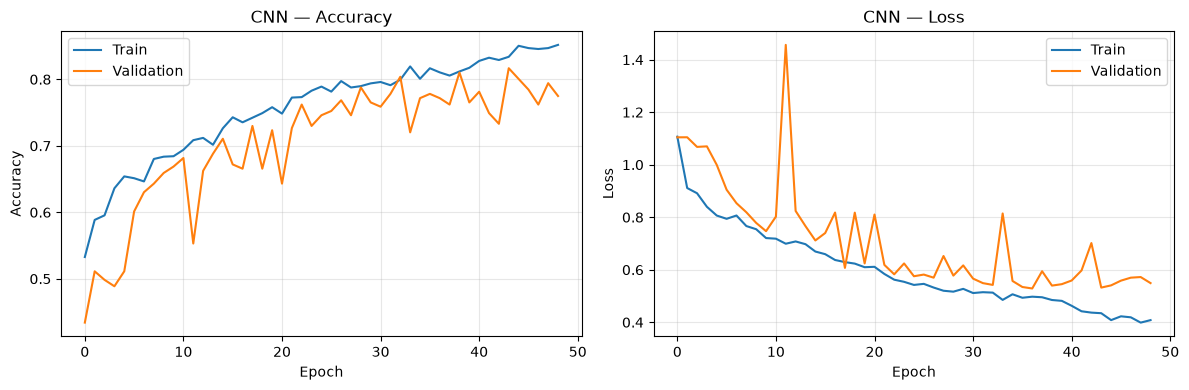

=== CNN ===
Train acc: 0.8222 | Val acc: 0.7717 | Test acc: 0.8167
Precision: 0.8229 | Recall: 0.8146 | F1: 0.8169  (macro, test)

              precision    recall  f1-score   support

       Daisy       0.92      0.81      0.86        95
        Rose       0.71      0.79      0.75        96
       Tulip       0.84      0.84      0.84       120

    accuracy                           0.82       311
   macro avg       0.82      0.81      0.82       311
weighted avg       0.82      0.82      0.82       311



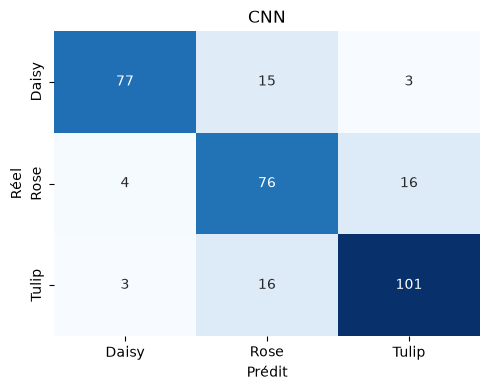

In [19]:
plot_history(hist_cnn, 'CNN')

register('CNN',
         cnn_model.predict(X_val, verbose=0),
         cnn_model.predict(X_test, verbose=0),
         cnn_model.predict(X_train, verbose=0))
plot_confusion('CNN')

## 6. Modèle de vote (ensemble)

On combine les trois modèles :

- **Vote dur** : chaque modèle vote pour une classe, la majorité l'emporte (si les 3 sont en désaccord, on suit le modèle ayant la meilleure accuracy de validation).
- **Vote doux** : moyenne des probabilités des trois modèles.
- **Vote pondéré** : moyenne pondérée, les poids sont choisis par recherche sur la **validation** (jamais sur le test).

## 7. Comparaison globale

In [25]:
summary = pd.DataFrame(results).T
summary['Écart Train-Test'] = summary['Train Acc'] - summary['Test Acc']
cols = ['Train Acc', 'Val Acc', 'Test Acc', 'Écart Train-Test', 'Precision', 'Recall', 'F1']
display(summary[cols].round(4))

,Train Acc,Val Acc,Test Acc,Écart Train-Test,Precision,Recall,F1
Softmax,0.7519,0.5563,0.5498,0.2021,0.5449,0.5466,0.5451
k-NN,NaN,0.5723,0.5080,NaN,0.5054,0.4955,0.4934
CNN,0.8222,0.7717,0.8167,0.0055,0.8229,0.8146,0.8169
Vote dur,NaN,0.7106,0.7042,NaN,0.7061,0.6992,0.7005
Vote doux,NaN,0.7363,0.7460,NaN,0.7438,0.7397,0.7379
Vote pondéré,NaN,0.7781,0.8103,NaN,0.8177,0.8084,0.8115


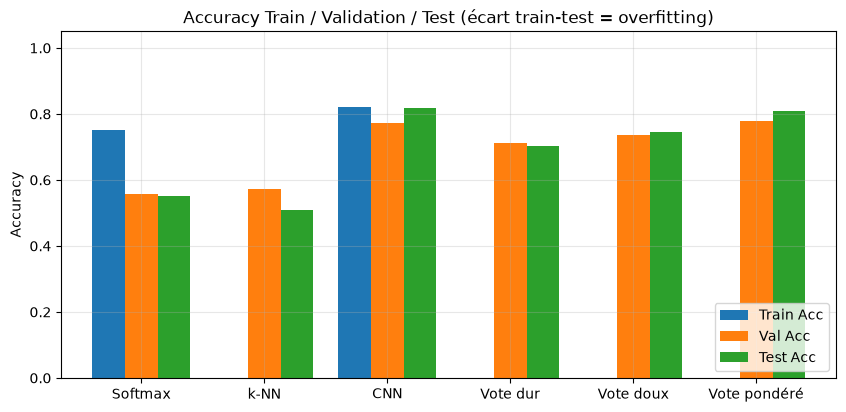

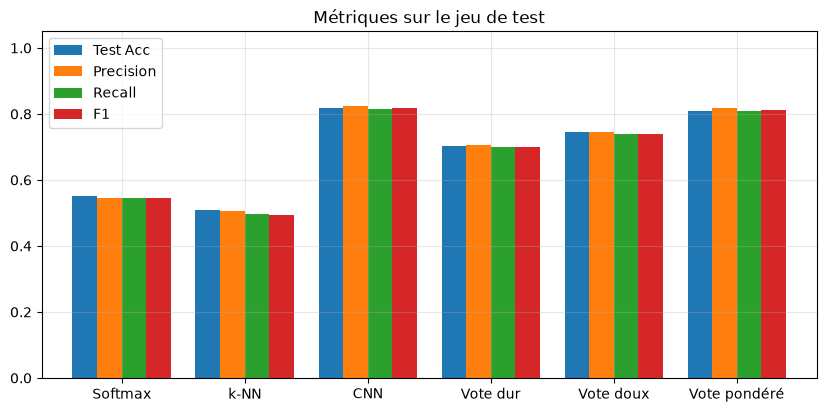

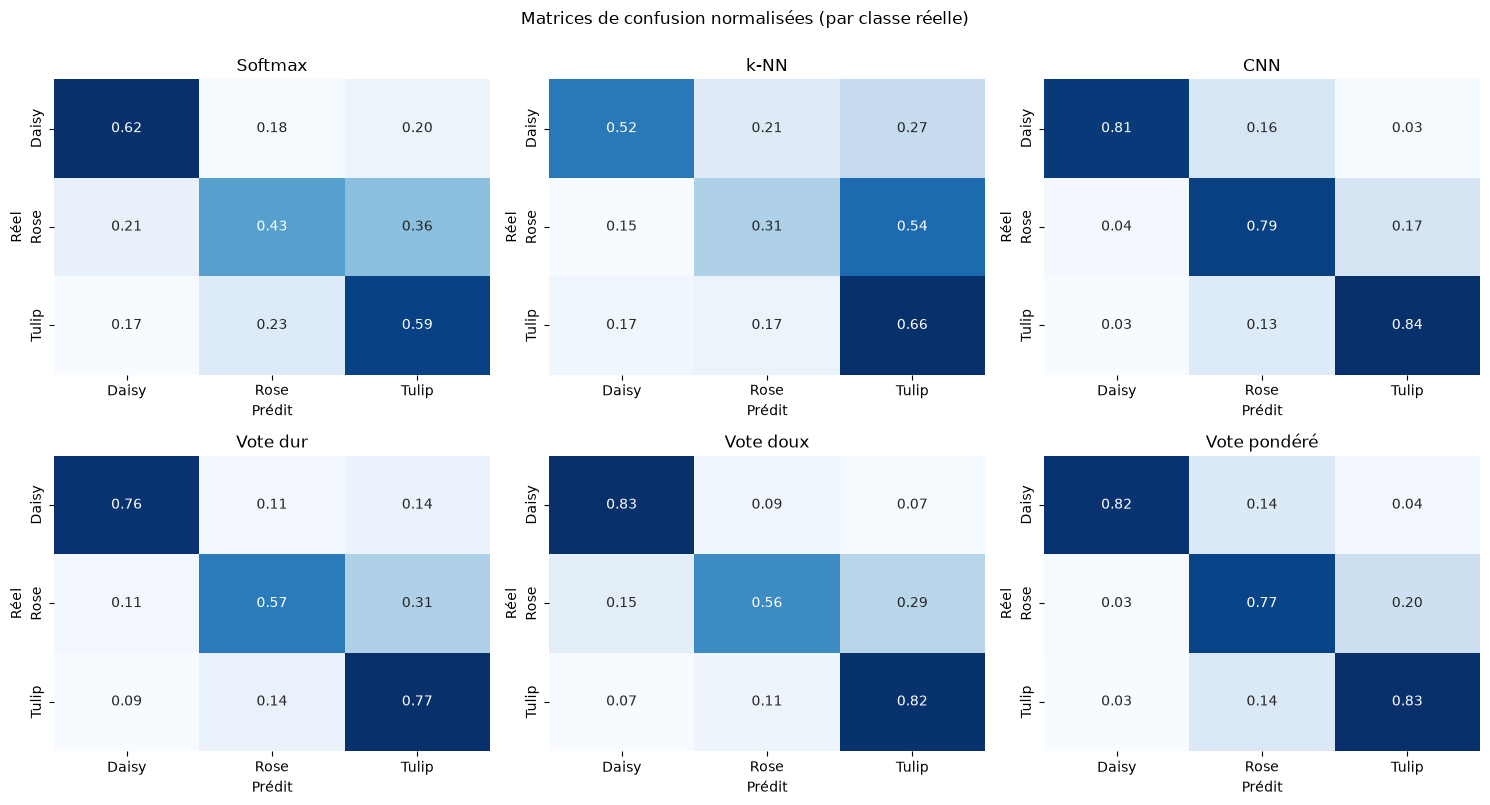

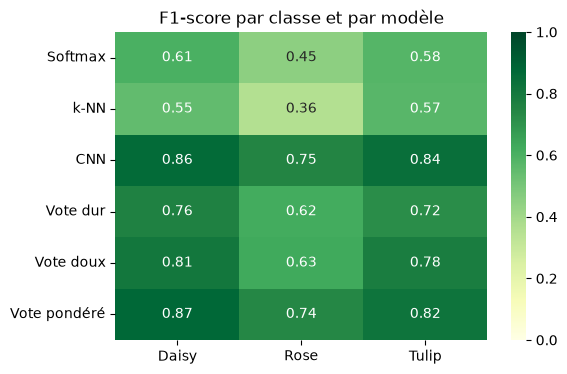

In [22]:
order = list(summary.index)

# (a) Train / Validation / Test : visualise directement l'overfitting
fig, ax = plt.subplots(figsize=(10, 4.5))
summary[['Train Acc', 'Val Acc', 'Test Acc']].plot(kind='bar', ax=ax, width=0.8)
ax.set(title='Accuracy Train / Validation / Test (écart train-test = overfitting)',
       ylabel='Accuracy', ylim=(0, 1.05))
plt.xticks(rotation=0); ax.legend(loc='lower right'); plt.show()

# (b) Métriques de test
fig, ax = plt.subplots(figsize=(10, 4.5))
summary[['Test Acc', 'Precision', 'Recall', 'F1']].plot(kind='bar', ax=ax, width=0.8)
ax.set(title='Métriques sur le jeu de test', ylim=(0, 1.05))
plt.xticks(rotation=0); plt.show()

# (c) Matrices de confusion normalisées
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, n in zip(axes.ravel(), order):
    plot_confusion(n, ax=ax, normalize=True)
plt.suptitle('Matrices de confusion normalisées (par classe réelle)', y=1.0); plt.tight_layout(); plt.show()

# (d) F1 par classe
f1_cls = summary[[f'F1 {c}' for c in class_names]].astype(float)
f1_cls.columns = class_names
plt.figure(figsize=(6, 4))
sns.heatmap(f1_cls, annot=True, fmt='.2f', cmap='YlGn', vmin=0, vmax=1)
plt.title('F1-score par classe et par modèle'); plt.gca().grid(False); plt.show()

Meilleur modèle : Vote pondéré — 252 erreurs sur 311 images de test


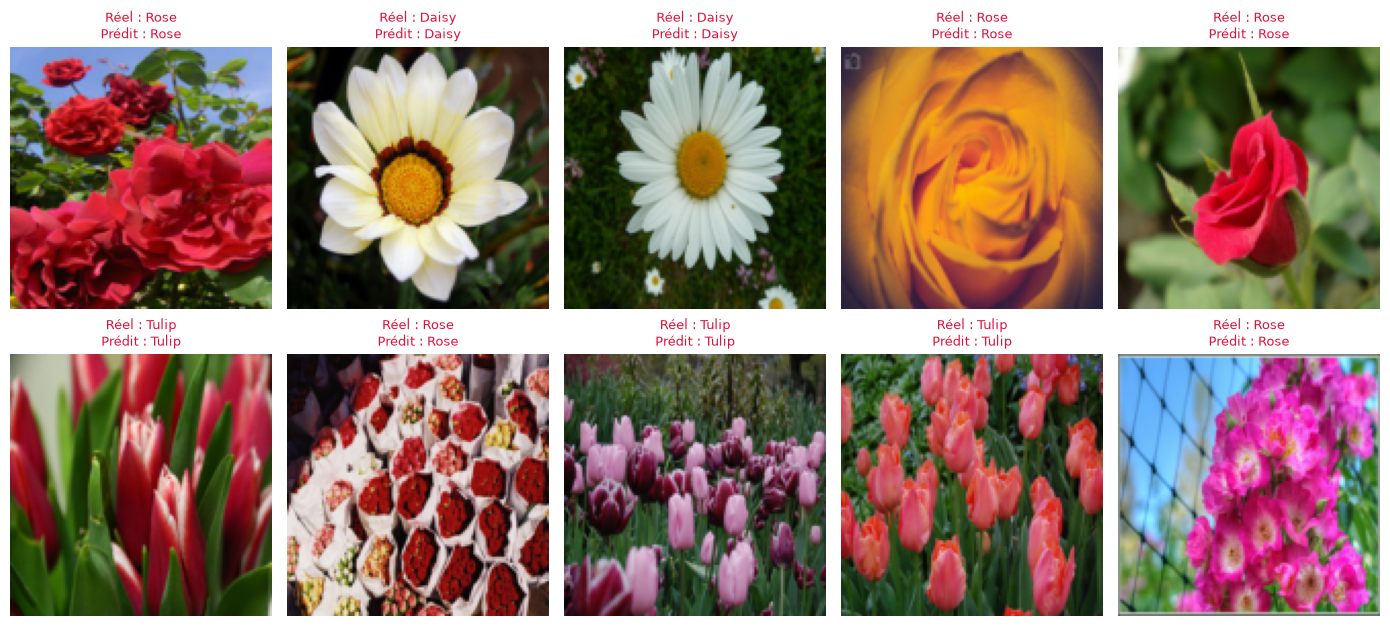

In [26]:
# Exemples mal classés par le meilleur modèle (selon l'accuracy de validation)
best_name = summary['Val Acc'].idxmax()
wrong = np.where(test_pred[best_name] == y_test)[0]
print(f"Meilleur modèle : {best_name} — {len(wrong)} erreurs sur {len(y_test)} images de test")

if len(wrong):
    n_show = min(10, len(wrong))
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax in axes.ravel(): ax.axis('off')
    for ax, i in zip(axes.ravel(), wrong[:n_show]):
        ax.imshow(X_test[i])
        ax.set_title(f"Réel : {class_names[y_test[i]]}\nPrédit : {class_names[test_pred[best_name][i]]}",
                     fontsize=9, color='crimson')
    plt.tight_layout(); plt.show()

In [24]:
# Sauvegardes
summary[cols].round(4).to_csv('results_summary.csv')
cnn_model.save('cnn_flowers.keras')
print("Sauvegardé : results_summary.csv, cnn_flowers.keras")

Sauvegardé : results_summary.csv, cnn_flowers.keras


## 8. Pistes pour aller plus loin (si l'accuracy du CNN reste insuffisante)

1. **Transfert d'apprentissage** (MobileNetV2 / EfficientNetB0 pré-entraîné sur ImageNet, couches gelées + petite tête de classification) : c'est de loin le plus gros gain possible sur 2 000 images ; on passe généralement à **90–95 %**.
2. **Features de couleur pour k-NN / Softmax** : histogrammes HSV (la couleur distingue très bien daisy / rose / tulip) concaténés aux pixels réduits.
3. **Plus de données** : utiliser aussi les classes `dandelion` et `sunflowers` en entraînement, ou augmenter davantage (`RandomTranslation`, `RandomBrightness`).
4. **Validation croisée stratifiée** (5 plis) pour des chiffres moins dépendants d'un seul split de 310 images de validation / test.
5. **Test-time augmentation** : moyenner les prédictions du CNN sur l'image et sa version retournée.